# GAIN - Polydispersity - DM4: nanoparticle polydispersity from Gatan DigitalMicrograph `.dm4` files

Dedicated pipeline for **Gatan DigitalMicrograph `.dm4`** (and `.dm3`) files. Pixel calibration (nm/px) and acquisition mode are read directly from the file's own metadata via HyperSpy -- there is no scale bar to detect: you only need to point it at a file (or a folder of files).

**Pipeline**: load `.dm4` + metadata -> normalize to 8-bit -> Otsu threshold (direction chosen automatically from the acquisition mode) -> watershed split of touching particles -> measure diameters -> polydispersity statistics + histogram + overlay.

**Dependencies**: `hyperspy`, `opencv-python-headless`, `numpy`, `scipy`, `scikit-image`, `matplotlib`, `pandas` (see `requirements.txt`).

**If no particles are found**: the pipeline does not crash -- it shows you the segmentation mask instead, so you can see why (wrong bright/dark-field guess, or filters too strict) and adjust the parameters in Configuration.

## Configuration

Set `mode` to choose what to analyze: **`"file"`** runs the *Single file* section on `file_path`, **`"folder"`** runs *Batch processing* on every `.dm4` file in `folder_path`. Only the section matching `mode` does anything, so **Run All Cells** is safe; the other section just prints a "Skipped" message. The remaining parameters have sensible defaults -- only touch them if particle detection doesn't work well (see the notes on each parameter).

In [1]:
mode = "folder"  # "file" -> analyze the single file in file_path | "folder" -> analyze every file in folder_path

file_path = "./Data/Gatan/NPs_0016.dm4"  # <-- path to a single .dm4 file (used by "Single file" section)
folder_path = "./Data/Gatan"               # <-- folder containing .dm4 files (used by "Batch processing" section)
outdir = "Result_Poly_dm4"

min_diam_px = 25          # minimum accepted particle diameter, in pixels (filters out noise)
min_circularity = 0.5     # minimum accepted circularity (1.0 = perfect circle)
min_peak_distance = 15    # minimum distance between particle centers for watershed, in px (lower for small/closely packed particles)
bright_particles_override = None  # None = auto-detect bright/dark-field from metadata; set True or False to force it if the guess is wrong

outdir = "Result_Poly_dm4"  # set to None to skip saving overlay.png/histogram.png to disk

assert mode in ("file", "folder"), "mode must be 'file' or 'folder'"

In [2]:
import os
import glob

import cv2
import numpy as np
import pandas as pd
from scipy import ndimage as ndi
from skimage.feature import peak_local_max
from skimage.segmentation import watershed
from skimage.measure import regionprops
import matplotlib.pyplot as plt
import hyperspy.api as hs

%matplotlib inline

## 1. Loading `.dm4` files and metadata

`load_dm4_image()` reads the pixel calibration (nm/px) from the file's axes, plus acquisition info (camera/detector, TEM vs STEM, magnification, voltage) from the DigitalMicrograph tags, and normalizes the raw float intensities to 8-bit. Mode guess: TEM (CCD camera) and bright-field STEM -> particles darker than the background; STEM signals whose name contains `DF` (`DF`, `ADF`, `HAADF`) -> dark-field, particles brighter than the background. Override with `bright_particles_override` in Configuration if the guess is wrong.

If the file has no spatial calibration (or it is in reciprocal units, i.e. a diffraction pattern) an explicit error is raised instead of guessing.

In [3]:
UNIT_TO_NM = {
    "nm": 1.0,
    "um": 1000.0,
    "µm": 1000.0,
    "pm": 0.001,
    "a": 0.1,
    "å": 0.1,
    "angstrom": 0.1,
    "m": 1e9,
}


def normalize_to_uint8(data, low_percentile=1.0, high_percentile=99.0):
    """
    Rescales an arbitrary-range array (e.g. raw CCD counts, possibly with
    negative values after dark/gain correction) to 0-255 uint8, clipping the
    extreme percentiles first so a few outlier pixels don't compress the
    contrast of the rest of the image.
    """
    lo, hi = np.percentile(data, [low_percentile, high_percentile])
    if hi <= lo:
        lo, hi = float(data.min()), float(data.max())
    clipped = np.clip(data, lo, hi)
    scaled = (clipped - lo) / (hi - lo + 1e-12) * 255.0
    return scaled.astype(np.uint8)


def find_image_tags(original_metadata):
    """Returns the ImageTags dict of the first image stored in a DigitalMicrograph file (or {})."""
    image_list = original_metadata.get("ImageList", {})
    for key in sorted(image_list):
        tags = image_list[key].get("ImageTags") if isinstance(image_list[key], dict) else None
        if isinstance(tags, dict):
            return tags
    return {}


def classify_darkfield(signal_name):
    """
    Guesses bright-field vs dark-field from the acquisition signal name.
    TEM CCD cameras (e.g. 'Orius SC200') and 'BF' STEM signals -> False
    (particles darker than background). STEM signals containing 'DF'
    ('DF', 'ADF', 'HAADF') -> True (particles brighter than background).
    """
    if not signal_name:
        return False
    return "DF" in str(signal_name).upper()


def load_dm4_image(path, signal_index=0):
    """
    Loads a Gatan DigitalMicrograph .dm4/.dm3 file with HyperSpy and returns
    (gray_uint8, nm_per_px, is_darkfield, info). Calibration and acquisition
    mode are read from the file's metadata -- no scale bar detection needed.
    If the file contains multiple signals, the one at signal_index is used
    (default: the first).
    """
    result = hs.load(path)
    signals = result if isinstance(result, list) else [result]
    if len(signals) > 1:
        print("Note: " + str(len(signals)) + " signals found in '" + path +
              "', using index " + str(signal_index) +
              " (" + str(signals[signal_index].metadata.General.title) + ")")
    s = signals[signal_index]

    if s.axes_manager.signal_dimension != 2:
        raise ValueError("'" + path + "' does not contain a 2D image (signal dimension = " +
                         str(s.axes_manager.signal_dimension) + ").")

    ax = s.axes_manager.signal_axes[0]
    units = str(ax.units).strip().replace("μ", "µ")
    factor = UNIT_TO_NM.get(units.lower())
    if factor is None:
        raise ValueError(
            "No usable spatial calibration in '" + path + "': axis units = '" + units +
            "' (diffraction pattern, or an uncalibrated image?). Cannot convert pixels to nm."
        )
    nm_per_px = float(ax.scale) * factor

    tags = find_image_tags(s.original_metadata.as_dictionary())
    microscope = tags.get("Microscope Info", {})
    databar = tags.get("DataBar", {})
    detector = databar.get("Signal Name") or databar.get("Device Name") or s.metadata.General.title
    is_darkfield = classify_darkfield(detector)

    gray = normalize_to_uint8(s.data)

    info = {
        "detector": detector,
        "illumination_mode": microscope.get("Illumination Mode"),
        "magnification": microscope.get("Formatted Indicated Mag"),
        "voltage": microscope.get("Formatted Voltage"),
        "raw_dtype": str(s.data.dtype),
        "raw_min": float(s.data.min()),
        "raw_max": float(s.data.max()),
    }
    return gray, nm_per_px, is_darkfield, info

## 2. Segmentation (Otsu + watershed)

In [4]:
def segment_and_split_particles(gray_img, min_peak_distance=15, bright_particles=False):
    """
    Segments particles on a uniform background and splits touching
    particles using watershed based on the distance transform.

    Parameters
    ----------
    gray_img : np.ndarray (2D, uint8)
    min_peak_distance : int
        Minimum distance (in pixels) between local maxima of the distance
        transform, used as markers for the watershed. Should be chosen
        based on the approximate particle radius (smaller if particles are
        small/closely packed).
    bright_particles : bool
        False for bright-field-style images where particles are darker
        than the background. True for dark-field/HAADF STEM images, where
        particles are the brightest pixels (Z-contrast).

    Returns
    -------
    labels_ws : np.ndarray (2D, int) - watershed labels (0 = background)
    mask : np.ndarray (2D, bool) - binary mask of the particles
    """
    blur = cv2.GaussianBlur(gray_img, (5, 5), 0)
    thresh_type = cv2.THRESH_BINARY if bright_particles else cv2.THRESH_BINARY_INV
    _, th = cv2.threshold(blur, 0, 255, thresh_type + cv2.THRESH_OTSU)

    kernel = np.ones((3, 3), np.uint8)
    th_clean = cv2.morphologyEx(th, cv2.MORPH_OPEN, kernel, iterations=1)
    th_clean = cv2.morphologyEx(th_clean, cv2.MORPH_CLOSE, kernel, iterations=1)
    mask = th_clean > 0

    dist = ndi.distance_transform_edt(mask)
    coords = peak_local_max(dist, min_distance=min_peak_distance, labels=mask,
                             exclude_border=False)
    markers_mask = np.zeros(dist.shape, dtype=bool)
    markers_mask[tuple(coords.T)] = True
    markers, _ = ndi.label(markers_mask)

    labels_ws = watershed(-dist, markers, mask=mask)
    return labels_ws, mask

## 3. Particle measurement

In [5]:
def measure_particles(labels_ws, nm_per_px, min_diam_px=25, min_circularity=0.5):
    """
    Computes area, equivalent diameter and circularity for each watershed
    region and filters out regions that are too small or not circular
    enough (typically noise fragments or edge artifacts).

    Returns
    -------
    list of dict, one per accepted particle, with keys:
        label, area_px, eq_diam_px, eq_diam_nm, circularity, solidity, centroid
    """
    props = regionprops(labels_ws)
    particles = []
    for p in props:
        area = p.area
        perim = p.perimeter if p.perimeter > 0 else 1
        circularity = 4 * np.pi * area / (perim ** 2)
        eq_diam_px = 2 * np.sqrt(area / np.pi)

        if eq_diam_px < min_diam_px:
            continue
        if circularity < min_circularity:
            continue

        particles.append({
            "label": p.label,
            "area_px": area,
            "eq_diam_px": eq_diam_px,
            "eq_diam_nm": eq_diam_px * nm_per_px,
            "circularity": circularity,
            "solidity": p.solidity,
            "centroid": p.centroid,  # (row, col)
        })
    return particles

## 4. Polydispersity statistics

In [6]:
def polydispersity_stats(diam_nm):
    """
    Computes polydispersity statistics from a non-empty array of
    diameters (in nm). Only ever called with at least one particle --
    analyze_emd_image() handles the zero-particle case separately.

    PDI here is defined as (sigma/mean)^2, the same convention typically
    used in DLS. It is a dimensionless metric: lower values indicate a
    more monodisperse sample (e.g. PDI < 0.05 - 0.1 in TEM).
    """
    diam_nm = np.asarray(diam_nm)
    mean_d = diam_nm.mean()
    std_d = diam_nm.std(ddof=1) if diam_nm.size > 1 else 0.0
    return {
        "n": len(diam_nm),
        "mean_nm": mean_d,
        "median_nm": float(np.median(diam_nm)),
        "std_nm": std_d,
        "cv_percent": std_d / mean_d * 100,
        "pdi": (std_d / mean_d) ** 2,
        "min_nm": float(diam_nm.min()),
        "max_nm": float(diam_nm.max()),
    }

## 5. Visualization

In [7]:
def draw_overlay(color_img, particles, out_path=None):
    overlay = color_img.copy()
    for p in particles:
        cy, cx = p["centroid"]
        r = p["eq_diam_px"] / 2
        cv2.circle(overlay, (int(round(cx)), int(round(cy))), int(round(r)),
                   (0, 0, 255), 2)
        cv2.circle(overlay, (int(round(cx)), int(round(cy))), 1, (0, 255, 0), 2)
    if out_path:
        cv2.imwrite(out_path, overlay)
    return overlay


def show_overlay(overlay_bgr, n_particles=None):
    """Displays a BGR (OpenCV) overlay image inline using matplotlib."""
    plt.figure(figsize=(8, 8))
    plt.imshow(cv2.cvtColor(overlay_bgr, cv2.COLOR_BGR2RGB))
    title = "Detected particles"
    if n_particles is not None:
        title += f" (N={n_particles})"
    plt.title(title)
    plt.axis("off")
    plt.show()


def plot_histogram(diam_nm, stats, out_path=None, material="nanoparticles", show=True):
    plt.figure(figsize=(7, 5))
    plt.hist(diam_nm, bins=30, color="#4C72B0", edgecolor="white")
    plt.axvline(stats["mean_nm"], color="crimson", linestyle="--", linewidth=1.5,
                label=f'Mean = {stats["mean_nm"]:.2f} nm')
    plt.xlabel("Particle diameter (nm)")
    plt.ylabel("Count")
    plt.title(
        f'Size distribution {material} (N={stats["n"]})\n'
        f'Std dev = {stats["std_nm"]:.2f} nm, CV = {stats["cv_percent"]:.1f}%, '
        f'PDI = {stats["pdi"]:.4f}'
    )
    plt.legend()
    plt.tight_layout()
    if out_path:
        plt.savefig(out_path, dpi=150)
    if show:
        plt.show()
    else:
        plt.close()

## Full pipeline (single file)

`analyze_dm4_image()` is purely computational (loads, segments, measures, computes stats) and never crashes on zero detected particles -- `stats`/`overlay` are simply `None` in that case. `show_results()` and `save_results()` handle displaying/saving, including showing the segmentation mask when nothing was detected, so you can see why.

In [9]:
def analyze_dm4_image(path, min_diam_px=25, min_circularity=0.5, min_peak_distance=15,
                       bright_particles_override=None, signal_index=0):
    """
    Runs the full pipeline on a single .dm4 file (load + metadata
    calibration, segmentation, measurement, statistics) and returns a
    dict: path, nm_per_px, is_darkfield, detector, info, gray, mask,
    particles, stats, overlay. If no particles are detected, stats and
    overlay are None -- use show_results() to see the segmentation mask and
    debug why (wrong bright/dark-field guess, or min_diam_px/min_circularity
    too strict) instead of crashing.
    """
    gray, nm_per_px, is_darkfield, info = load_dm4_image(path, signal_index=signal_index)
    if bright_particles_override is not None:
        is_darkfield = bright_particles_override

    labels_ws, mask = segment_and_split_particles(
        gray, min_peak_distance=min_peak_distance, bright_particles=is_darkfield,
    )
    particles = measure_particles(
        labels_ws, nm_per_px=nm_per_px,
        min_diam_px=min_diam_px, min_circularity=min_circularity,
    )

    stats = None
    overlay = None
    if particles:
        diam_nm = np.array([p["eq_diam_nm"] for p in particles])
        stats = polydispersity_stats(diam_nm)
        color_img = cv2.cvtColor(gray, cv2.COLOR_GRAY2BGR)
        overlay = draw_overlay(color_img, particles)

    return {
        "path": path,
        "nm_per_px": nm_per_px,
        "is_darkfield": is_darkfield,
        "detector": info["detector"],
        "info": info,
        "gray": gray,
        "mask": mask,
        "particles": particles,
        "stats": stats,
        "overlay": overlay,
    }


def show_results(result, material="nanoparticles"):
    """
    Displays the metadata summary and, if particles were found, the
    overlay + size histogram. If none were found, shows the segmentation
    mask instead so you can see why.
    """
    info = result["info"]
    print("File: " + result["path"])
    print("Acquisition: " + str(info["illumination_mode"]) + " | camera/signal: " + str(info["detector"]) +
          " | mag: " + str(info["magnification"]) + " | " + str(info["voltage"]))
    print("Mode used: " + ("dark-field (bright particles)" if result["is_darkfield"]
                           else "bright-field (dark particles)"))
    print("Calibration: " + format(result["nm_per_px"], ".4f") + " nm/px")

    if not result["particles"]:
        print("No particles detected -- showing the segmentation mask for debugging. "
              "Try bright_particles_override, or relax min_diam_px / min_circularity.")
        plt.figure(figsize=(8, 8))
        plt.imshow(result["mask"], cmap="gray")
        plt.title("Segmentation mask (no particles passed the filters)")
        plt.axis("off")
        plt.show()
        return

    show_overlay(result["overlay"], n_particles=result["stats"]["n"])
    diam_nm = np.array([p["eq_diam_nm"] for p in result["particles"]])
    plot_histogram(diam_nm, result["stats"], material=material)


def save_results(result, outdir, material="nanoparticles"):
    """Saves overlay.png and histogram.png for one result into outdir (skipped if no particles were found)."""
    if not result["particles"]:
        print("Skipping save for '" + result["path"] + "': no particles detected.")
        return
    os.makedirs(outdir, exist_ok=True)
    cv2.imwrite(os.path.join(outdir, "overlay.png"), result["overlay"])
    diam_nm = np.array([p["eq_diam_nm"] for p in result["particles"]])
    plot_histogram(diam_nm, result["stats"], os.path.join(outdir, "histogram.png"),
                    material=material, show=False)

## Run: single file

Uses `file_path` from Configuration. Runs only when `mode = "file"`.

In [ ]:
from IPython.display import display

if mode != "file":
    print("Skipped: mode = '" + mode + "'. Set mode = 'file' in Configuration to run this section.")
else:
    result = analyze_dm4_image(
        file_path,
        min_diam_px=min_diam_px, min_circularity=min_circularity, min_peak_distance=min_peak_distance,
        bright_particles_override=bright_particles_override,
    )

    show_results(result)

    if outdir:
        save_results(result, outdir)

    display(result["stats"])

## Batch processing (multiple `.dm4` files)

Uses `folder_path` from Configuration. Every `.dm4` / `.dm3` file directly inside that folder is analyzed (each one is calibrated from its own metadata, so magnifications can differ between files); files with 0 detected particles are kept in the results (not skipped) so you can inspect them, files that error out unexpectedly (e.g. no spatial calibration) are skipped with a printed warning. Runs only when `mode = "folder"`.

In [10]:
def analyze_dm4_folder(folder_path, min_diam_px=25, min_circularity=0.5, min_peak_distance=15,
                        bright_particles_override=None, signal_index=0):
    """
    Runs analyze_dm4_image() on every .dm4/.dm3 file directly inside
    folder_path (non-recursive) and returns a dict {file_name: result}.
    """
    dm_paths = sorted({
        p for pattern in ("*.dm4", "*.dm3")
        for p in glob.glob(os.path.join(folder_path, pattern))
    })
    if not dm_paths:
        raise FileNotFoundError("No .dm4/.dm3 files found in: " + folder_path)

    results = {}
    for path in dm_paths:
        name = os.path.splitext(os.path.basename(path))[0]
        try:
            res = analyze_dm4_image(
                path, min_diam_px=min_diam_px, min_circularity=min_circularity,
                min_peak_distance=min_peak_distance,
                bright_particles_override=bright_particles_override,
                signal_index=signal_index,
            )
        except Exception as exc:
            print("[SKIPPED] " + name + ": " + str(exc))
            continue

        results[name] = res
        if res["stats"] is None:
            print(name + ": 0 particles detected (camera/signal: " + str(res["detector"]) +
                  ", dark-field: " + str(res["is_darkfield"]) + ")")
        else:
            s = res["stats"]
            print(name + ": N=" + str(s["n"]) + ", mean=" + format(s["mean_nm"], ".2f") +
                  " nm, CV=" + format(s["cv_percent"], ".1f") + "%, PDI=" + format(s["pdi"], ".4f"))

    return results


def summarize_folder_results(results):
    """Builds a one-row-per-file summary table (rows with 0 particles show n=0 and NaN elsewhere)."""
    rows = []
    for name, res in results.items():
        row = {
            "image": name,
            "magnification": res["info"]["magnification"],
            "nm_per_px": res["nm_per_px"],
            "is_darkfield": res["is_darkfield"],
        }
        if res["stats"] is not None:
            row.update(res["stats"])
        else:
            row["n"] = 0
        rows.append(row)
    return pd.DataFrame(rows).set_index("image").sort_index()

### Run batch analysis

NPs_0007: N=243, mean=16.02 nm, CV=15.2%, PDI=0.0230
NPs_0008: N=691, mean=15.93 nm, CV=16.2%, PDI=0.0262
NPs_0009: N=1433, mean=15.18 nm, CV=13.7%, PDI=0.0189
NPs_0015: N=41, mean=17.00 nm, CV=13.1%, PDI=0.0171
NPs_0016: N=372, mean=16.51 nm, CV=16.8%, PDI=0.0282
File: ./Data/Gatan\NPs_0007.dm4
Acquisition: TEM | camera/signal: Orius SC200 | mag: 30kx | 120kV
Mode used: bright-field (dark particles)
Calibration: 0.1655 nm/px


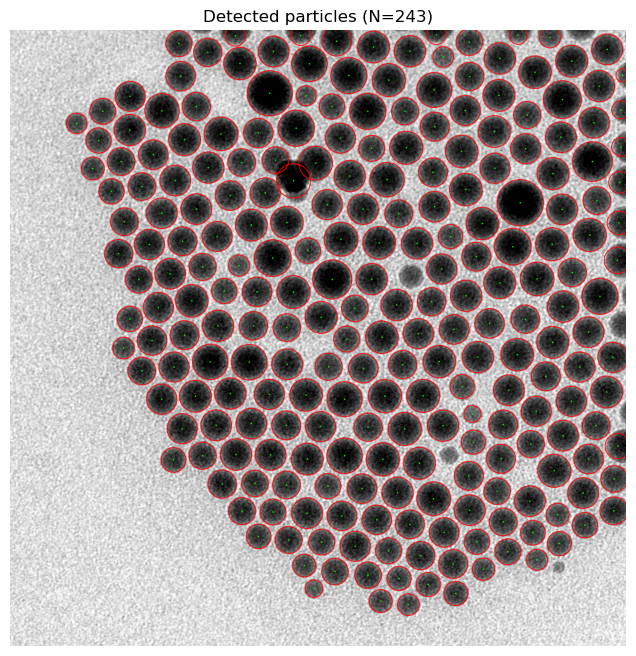

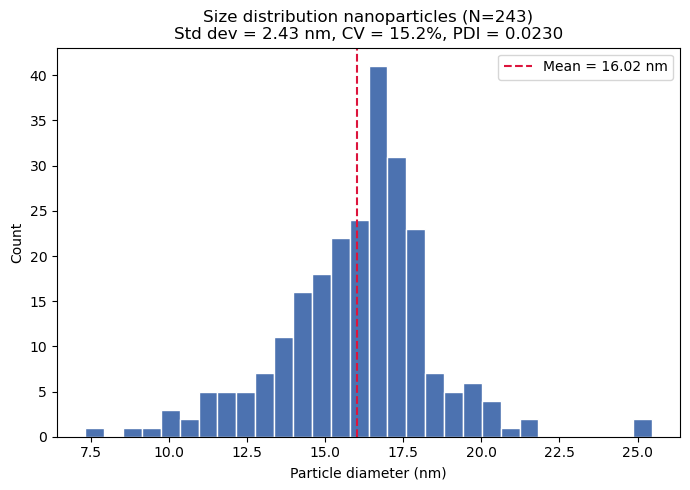

File: ./Data/Gatan\NPs_0008.dm4
Acquisition: TEM | camera/signal: Orius SC200 | mag: 20kx | 120kV
Mode used: bright-field (dark particles)
Calibration: 0.2710 nm/px


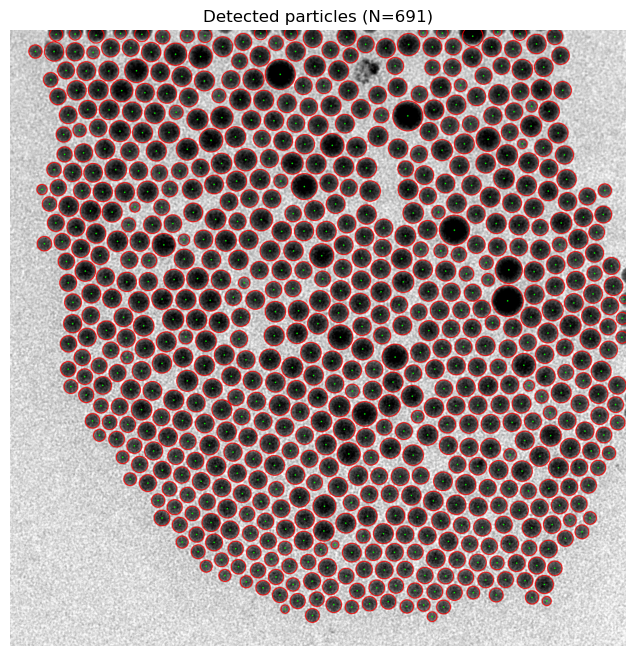

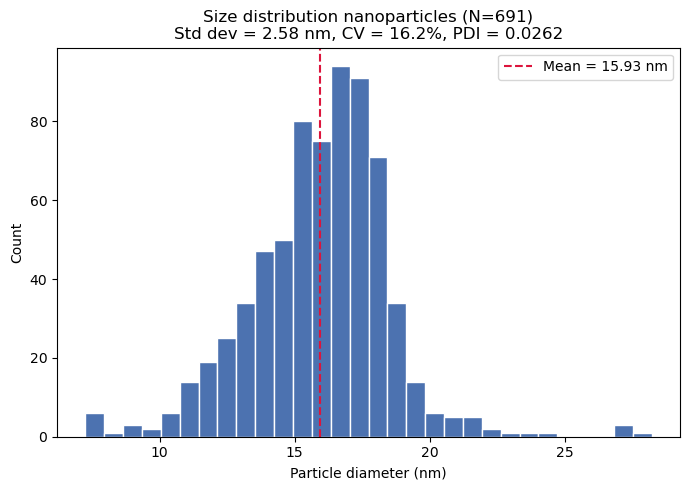

File: ./Data/Gatan\NPs_0009.dm4
Acquisition: TEM | camera/signal: Orius SC200 | mag: 12kx | 120kV
Mode used: bright-field (dark particles)
Calibration: 0.4300 nm/px


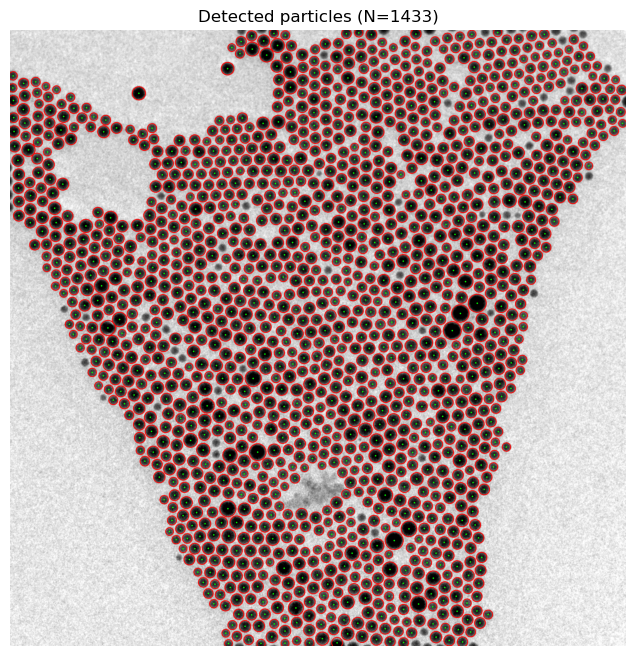

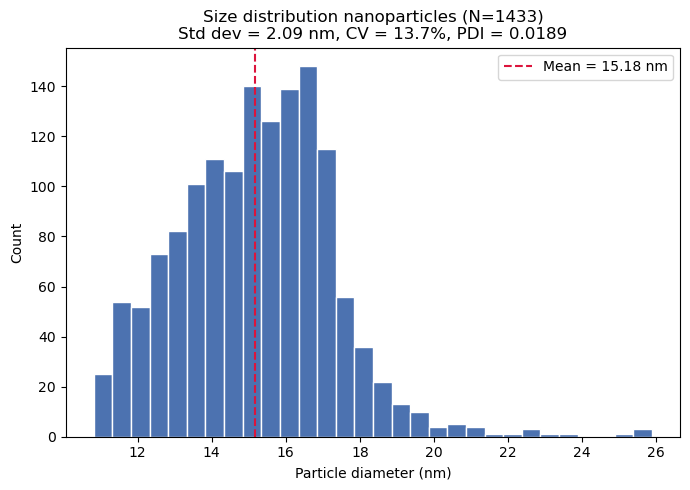

File: ./Data/Gatan\NPs_0015.dm4
Acquisition: TEM | camera/signal: Orius SC200 | mag: 30kx | 120kV
Mode used: bright-field (dark particles)
Calibration: 0.1655 nm/px


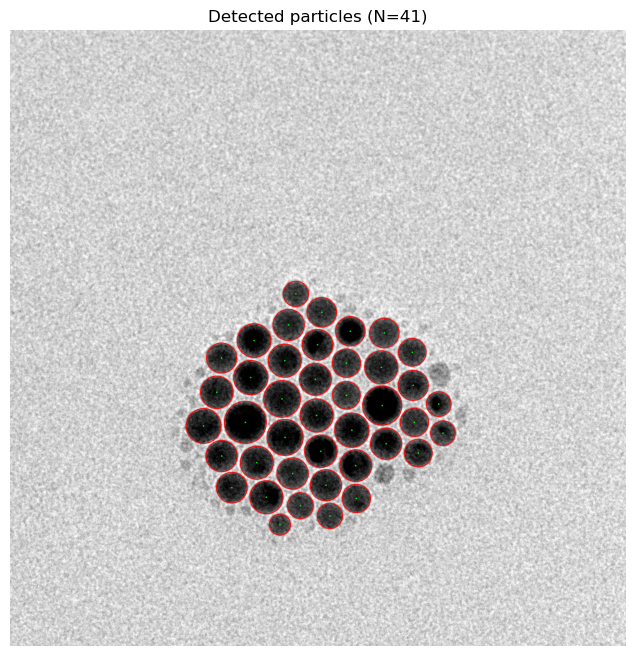

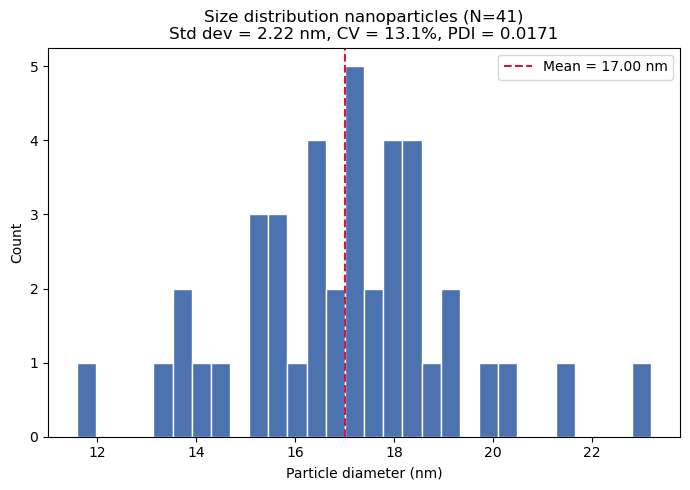

File: ./Data/Gatan\NPs_0016.dm4
Acquisition: TEM | camera/signal: Orius SC200 | mag: 20kx | 120kV
Mode used: bright-field (dark particles)
Calibration: 0.2710 nm/px


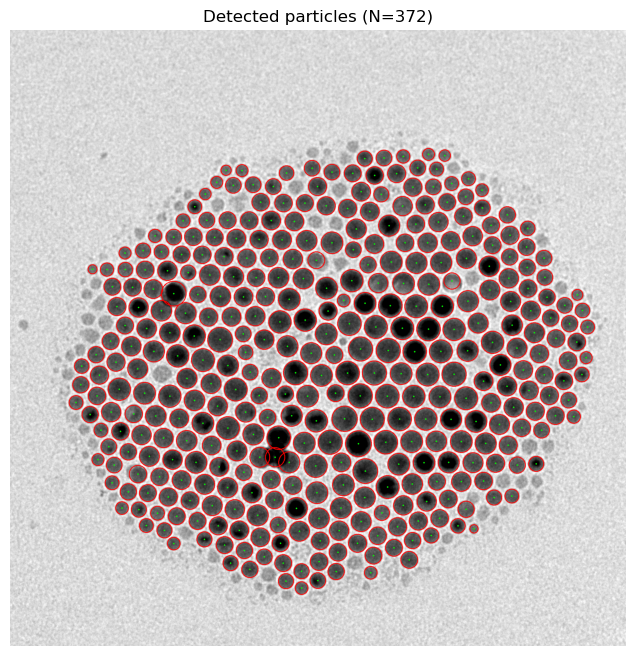

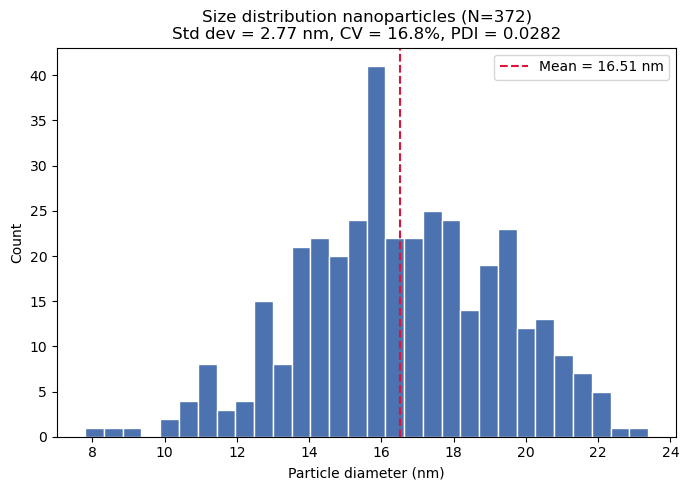

,magnification,nm_per_px,is_darkfield,n,mean_nm,median_nm,std_nm,cv_percent,pdi,min_nm,max_nm
image,,,,,,,,,,,
NPs_0007,30kx,0.165498,False,243,16.020896,16.404813,2.429216,15.162798,0.022991,7.323610,25.451387
NPs_0008,20kx,0.271005,False,691,15.931521,16.230293,2.577445,16.178272,0.026174,7.242931,28.216281
NPs_0009,12kx,0.429984,False,1433,15.181830,15.235110,2.087147,13.747662,0.018900,10.816465,25.892688
NPs_0015,30kx,0.165498,False,41,16.996327,17.103156,2.221347,13.069570,0.017081,11.587171,23.195399
NPs_0016,20kx,0.271005,False,372,16.514509,16.357978,2.771628,16.782988,0.028167,7.802314,23.380961


In [11]:
from IPython.display import display

if mode != "folder":
    print("Skipped: mode = '" + mode + "'. Set mode = 'folder' in Configuration to run this section.")
else:
    folder_results = analyze_dm4_folder(
        folder_path,
        min_diam_px=min_diam_px, min_circularity=min_circularity, min_peak_distance=min_peak_distance,
        bright_particles_override=bright_particles_override,
    )

    for name, res in folder_results.items():
        show_results(res)
        if outdir:
            save_results(res, os.path.join(outdir, name))

    summary = summarize_folder_results(folder_results)
    display(summary)

### Combined size distribution (all files pooled)

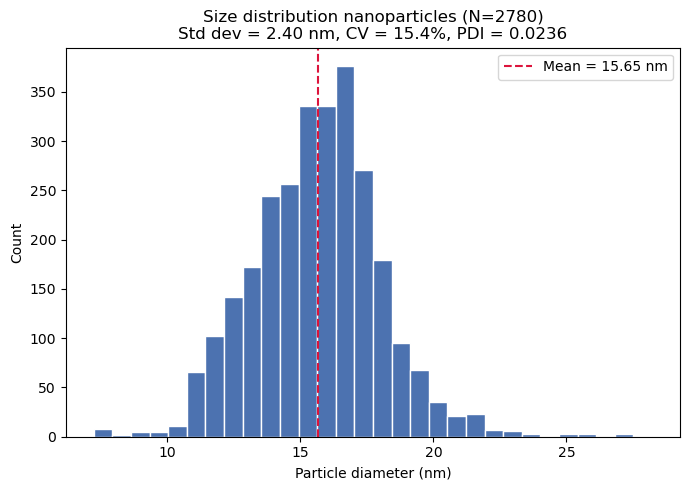

{'n': 2780,
 'mean_nm': 15.646607259244453,
 'median_nm': 15.721416055361269,
 'std_nm': 2.4033603562224926,
 'cv_percent': 15.360265113080793,
 'pdi': 0.02359377443441269,
 'min_nm': 7.242931437128461,
 'max_nm': 28.21628065409327}

In [12]:
from IPython.display import display

if mode != "folder":
    print("Skipped: mode = '" + mode + "'. Set mode = 'folder' in Configuration to run this section.")
else:
    particle_groups = [
        np.array([p["eq_diam_nm"] for p in res["particles"]])
        for res in folder_results.values() if res["particles"]
    ]
    if particle_groups:
        all_diam_nm = np.concatenate(particle_groups)
        combined_stats = polydispersity_stats(all_diam_nm)
        plot_histogram(
            all_diam_nm, combined_stats,
            out_path=os.path.join(outdir, "combined_histogram.png") if outdir else None,
        )
        display(combined_stats)
    else:
        print("No particles detected in any file -- nothing to combine.")